In [99]:
import pandas as pd #pandas organizes that data into a clean,readable table,manipulating the data.
import numpy as np #numpy works with the numerical and mathematical part,handles the underlying mat and raw arrays
import seaborn as sns #builds beautiful statistical charts out of your data table quickly to visualize the data.
import matplotlib.pyplot as plt #matplotlib fine-tunes the charts specific details(labels,limits and sizes)before you save it. 
import warnings
warnings.filterwarnings("ignore")

In [100]:
#our data is in the excel file to work on the data we have to call data pd.read_excel from pandas
df = pd.read_excel("Flight_Fare.xlsx") 

In [101]:
df.head()#will show the first 5 rows of the dataset.

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [102]:
pd.set_option("display.max_columns",None)

In [103]:
df.tail()#presents the last 5 rows of the datasets.

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [104]:
df.info()#provides the information of each columns.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [105]:
df.describe()#provides the statical information of the dataset

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [106]:
df.describe(include ="O")#presents statistical categorical data of the datasets the capital letter O,which is stands for the Objects.

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


## __Exploratory data analysis__

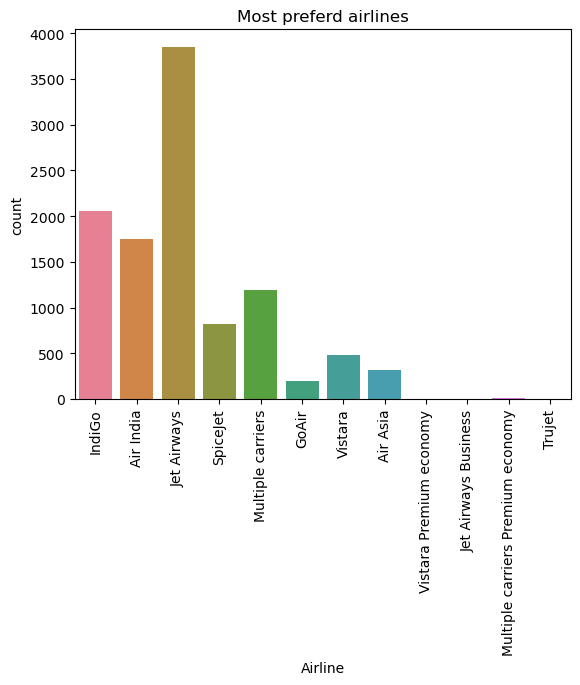

In [107]:
sns.countplot(x=df.Airline, hue=df.Airline)#ploting countplot of airline showing the number of occurrences (frequency) of each airline in the dataset.
plt.xticks(rotation=90)#This code rotates the x-axis labels by 90 degrees, making them vertical for better readability.
plt.title("Most preferd airlines")
plt.show()#for display graph 


# __Insights__
* Jet Airways is overwhelmingly the most preferred airline in dataset.
* Indigo holds the second most spot with a count of just over 2000.
* premium & luxury economy classes (and tiny regional lines like trujet)have almost
 zero presence,showing this dataset is heavily skewed towards standard economy travel

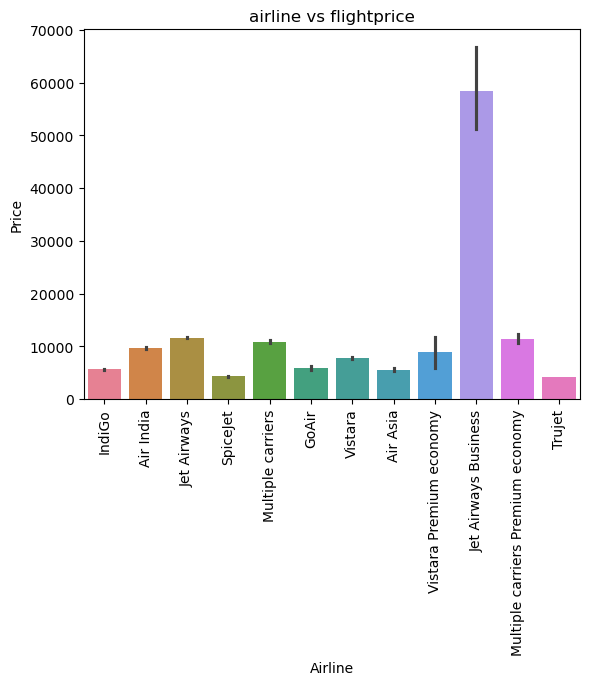

In [108]:
sns.barplot(x=df.Airline,y=df.Price,hue=df.Airline)
plt.title("airline vs flightprice")
plt.xticks(rotation=90)
plt.show()

# _Insights_
This graph shows that Jet Airways Business tickets are by far the most expensive, 
 while all other airlines and ticket types
are much cheaper and priced similarly to each other.

Text(0.5, 1.0, 'Source of Airline')

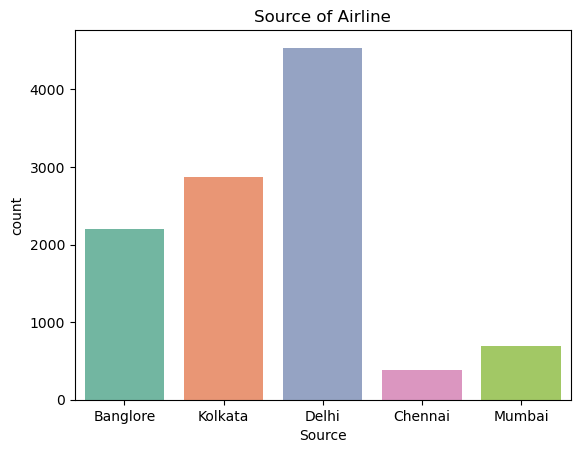

In [109]:
sns.countplot(x=df.Source,hue=df.Source,palette='Set2')#ploting countplot of source 
plt.title("Source of Airline")

# _Insight_
* Most Popular starting point:Delhi is the most frequent starting city (source) for the flights with count over 4000 flights
* kolkata is the second most common starting point(around 3000 flights and banglore around 2,200 flights)
* least popular starting points: chennai and Mumbai have lowest number of starting flights both are under the 1000 mark.

In [111]:
days_df = df[["Airline","Date_of_Journey","Price"]].copy()#copy function ensures that this new dataframe(days_df)is a completely independent copy.
days_df.head()

,Airline,Date_of_Journey,Price
0,IndiGo,24/03/2019,3897
1,Air India,1/05/2019,7662
2,Jet Airways,9/06/2019,13882
3,IndiGo,12/05/2019,6218
4,IndiGo,01/03/2019,13302


In [112]:
days_df["Date_of_Journey"]=pd.to_datetime(days_df["Date_of_Journey"],format="%d/%m/%Y")
days_df["weekdays"]=days_df["Date_of_Journey"].dt.day_name()
days_df["weekend"]=days_df["weekdays"].apply(lambda day:1 if day == "Sunday" else 0)
days_df.head()

,Airline,Date_of_Journey,Price,weekdays,weekend
0,IndiGo,2019-03-24,3897,Sunday,1
1,Air India,2019-05-01,7662,Wednesday,0
2,Jet Airways,2019-06-09,13882,Sunday,1
3,IndiGo,2019-05-12,6218,Sunday,1
4,IndiGo,2019-03-01,13302,Friday,0


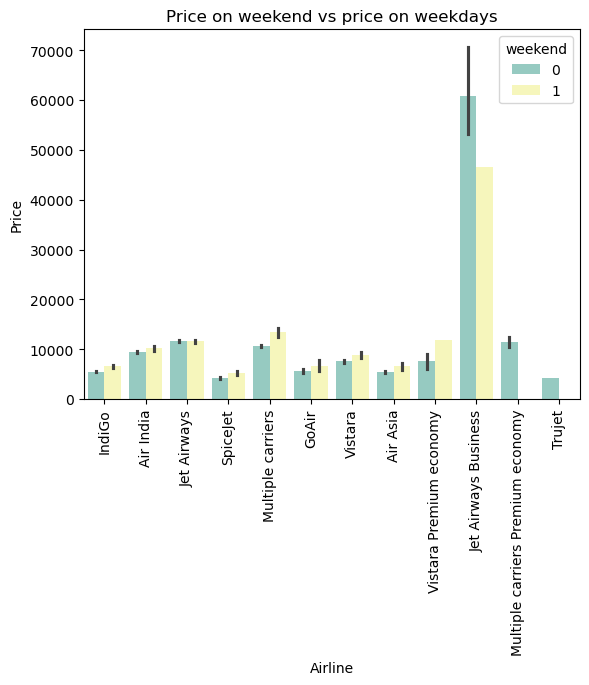

In [113]:
sns.barplot(x=df.Airline,y=df.Price,hue=days_df.weekend,palette='Set3')
plt.title("Price on weekend vs price on weekdays")
plt.xticks(fontsize=10,rotation=90)
plt.show()          

# _Insights_
* Flight tickets Price are more high on the weekends.
* Weekdays have Average Price of flights

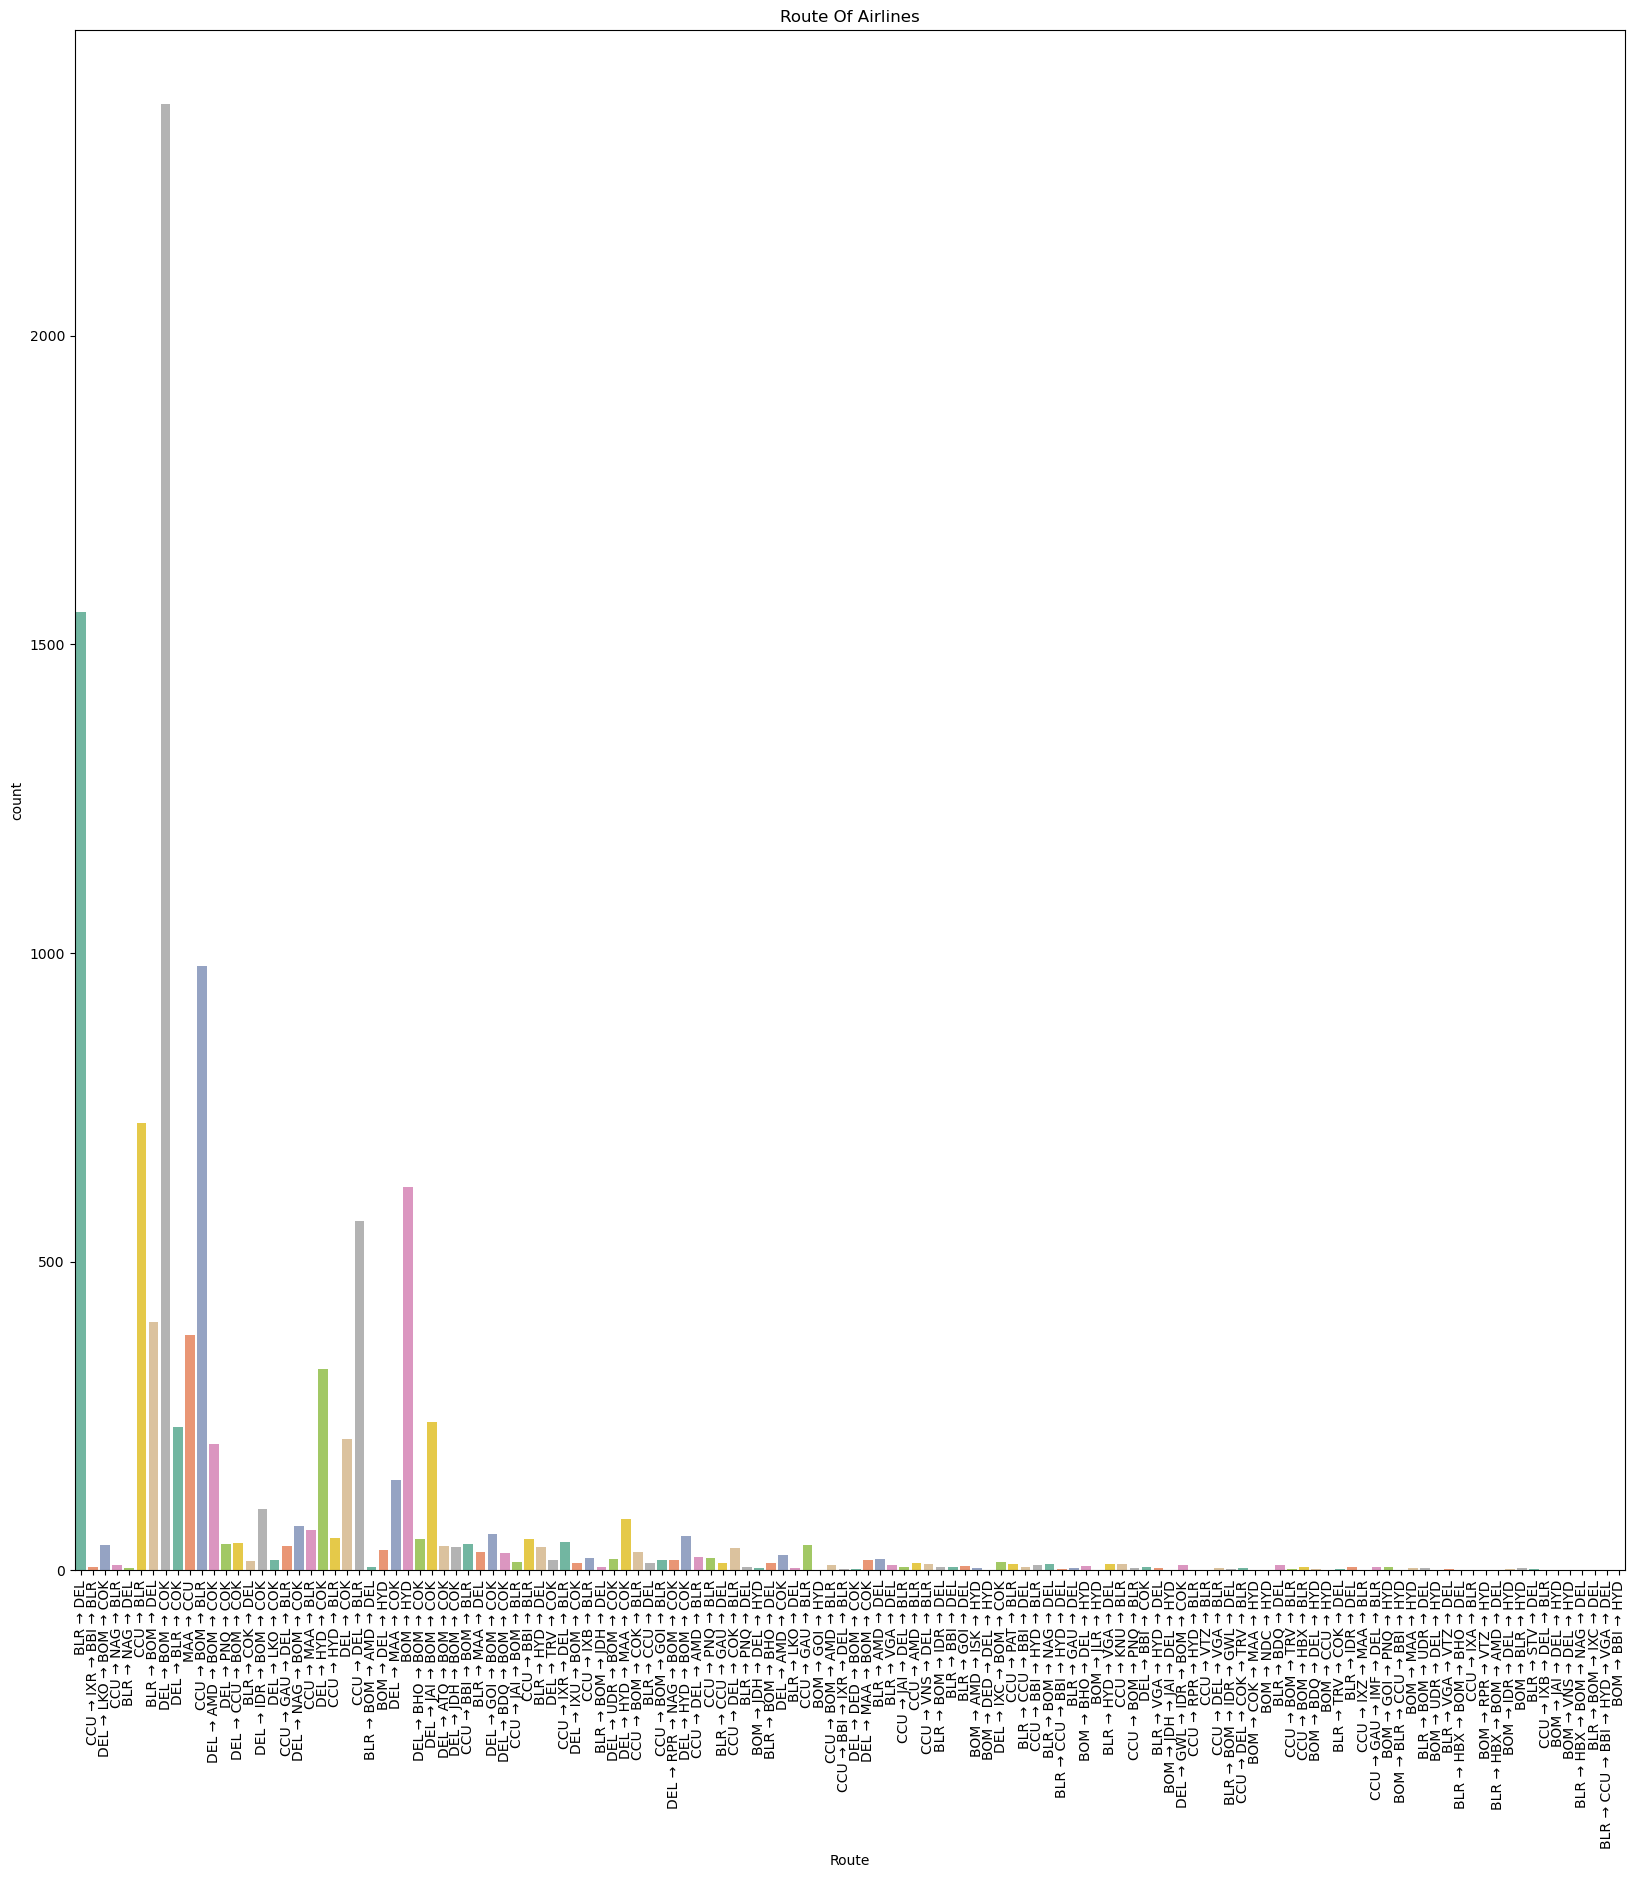

In [114]:
plt.figure(figsize=(20,20))
sns.countplot(x=df.Route,palette='Set2')
plt.title("Route Of Airlines")
plt.xticks(fontsize=10,rotation=90)
plt.yticks(fontsize=10)
plt.show()
           

# _Insights_
* Most frequent route is Del-Bom-Cok more then 23% flights route is Del-Bom-Cok and rest 15% is from the BLR-DEL
* most of airline having 2 stopage
* most of the flights are from delhi and landing cochin
* the airlines arrivals from Delhi and Departure in cochin they having 2 stopage
  
  

Text(0.5, 1.0, 'Total Stops of Flights')

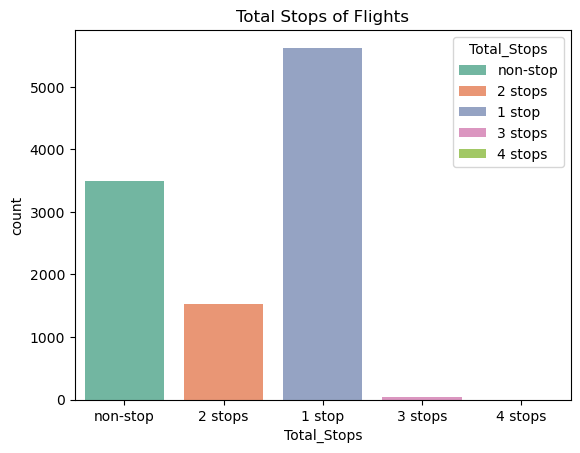

In [115]:
sns.countplot(x=df.Total_Stops,hue=df.Total_Stops,palette='Set2')
plt.title("Total Stops of Flights")

# _Insights_
* Flights with 1 stops are by far the most frequent in this dataset.
* Non-Stop flights represent the second largest category,totaling around 3,500.
* Flights requiring 2 stops are noticeably less common.
* flights with 3 stops and 4 stops are extreamly rareappearing as barely visible lines on the baseline of the chart.

# _Final Conclusion of Insights_
* Jet Airways is the most preferred and frequent airline in the dataset,closely followed by Indigo in second place
  with count of just over 2000.
* premium/Economy classes and tiny regional lines (like Trujet) have almost Zero presence .
* Jet Airways Business class Tickets are by far most expensive,while all other airlines and ticket types
  

# _Data Preprocessing_

In [116]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [117]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [118]:
df.loc[df["Route"].isnull()]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [119]:
df.Route.value_counts()

Route
DEL → BOM → COK          2376
BLR → DEL                1552
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
                         ... 
CCU → VTZ → BLR             1
CCU → IXZ → MAA → BLR       1
BOM → COK → MAA → HYD       1
BOM → CCU → HYD             1
BOM → BBI → HYD             1
Name: count, Length: 128, dtype: int64

In [120]:
df.Route.mode()

0    DEL → BOM → COK
Name: Route, dtype: object

In [121]:
df.loc[df["Route"].isnull(),"Route"]=df.Route.mode()[0]

In [122]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [123]:
df[9039:]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,DEL → BOM → COK,09:45,09:25 07 May,23h 40m,NaN,No info,7480
9040,Air India,21/03/2019,Delhi,Cochin,DEL → LKO → BOM → COK,12:20,19:15 22 Mar,30h 55m,2 stops,No info,10703
9041,Multiple carriers,18/05/2019,Delhi,Cochin,DEL → BOM → COK,11:30,21:00,9h 30m,1 stop,No info,13727
9042,Jet Airways,12/05/2019,Kolkata,Banglore,CCU → BOM → BLR,20:00,09:20 13 May,13h 20m,1 stop,No info,14388
9043,Air India,6/06/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,01:20 07 Jun,15h 20m,2 stops,No info,13033
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [124]:
df.Total_Stops.mode()[0]

'1 stop'

In [125]:
df.loc[df["Total_Stops"].isnull(),"Total_Stops"] = df.Total_Stops.mode()[0]

In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10683 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10683 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [127]:
df["Journey_day"] = pd.to_datetime(df.Date_of_Journey,format="%d/%m/%Y").dt.day
df["Journey_month"] = pd.to_datetime(df.Date_of_Journey,format="%d/%m/%Y").dt.month

In [128]:
df.head(1)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3


In [129]:
df["Dep_hours"] = pd.to_datetime(df.Dep_Time).dt.hour
df["Dep_mins"] = pd.to_datetime(df.Dep_Time).dt.minute

In [130]:
df["Arrival_Time"]=pd.to_datetime(df.Arrival_Time).dt.hour
df["Arrival_Time"]=pd.to_datetime(df.Arrival_Time).dt.minute

In [131]:
duration = list(df["Duration"])#creating new duration list column
for i in range(len(duration)):
    if len(duration[i].split()) !=2: # checking if duration having only hours and minutes
        if "h" in duration[i]:
            duration[i] = duration[i].strip()+" 0m" #adding 0minutes
        else:
            duration[i] = "0h "+duration[i] #adding ohours
Duration_hours = []# create new variable for duration hours
Duration_mins = []# create new variable for duration minutes
for i in range(len(duration)):
    Duration_hours.append(int(duration[i].split(sep = "h")[0])) #get all hours value in Duration_hours
    Duration_mins.append(int(duration[i].split(sep = "m")[0].split()[-1]))#get all minutes value in Duration_mins
    
df["Duration_hours"] = Duration_hours  #adding Duration_hours columns in data
df["Duration_mins"] = Duration_mins  #adding Duration_mins columns in data

In [132]:
duration = list(df["Duration"])

for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if "h" in duration[i]:
            duration[i] = duration[i].strip() + " 0m"
        else:
            duration[i] = "0h " + duration[i]   # <-- space added

duration_hours = []
duration_mins = []

for i in range(len(duration)):
    duration_hours.append(int(duration[i].split("h")[0]))
    duration_mins.append(int(duration[i].split("m")[0].split()[-1]))

df["Duration_hours"] = duration_hours
df["Duration_mins"] = duration_mins

In [133]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Duration_hours,Duration_mins
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,0,2h 50m,non-stop,No info,3897,24,3,22,20,2,50
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,0,7h 25m,2 stops,No info,7662,1,5,5,50,7,25
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,0,19h,2 stops,No info,13882,9,6,9,25,19,0
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,0,5h 25m,1 stop,No info,6218,12,5,18,5,5,25
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,0,4h 45m,1 stop,No info,13302,1,3,16,50,4,45


In [134]:
df.drop(["Date_of_Journey","Dep_Time","Arrival_Time","Duration","Route","Additional_Info"],axis=1,inplace=True)

In [135]:
df.head()

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,non-stop,3897,24,3,22,20,2,50
1,Air India,Kolkata,Banglore,2 stops,7662,1,5,5,50,7,25
2,Jet Airways,Delhi,Cochin,2 stops,13882,9,6,9,25,19,0
3,IndiGo,Kolkata,Banglore,1 stop,6218,12,5,18,5,5,25
4,IndiGo,Banglore,New Delhi,1 stop,13302,1,3,16,50,4,45


# __Conversion of categorical Variables__

Airline

In [136]:
df.Airline.value_counts()

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

Text(0.5, 1.0, 'Airlines vs Price in Catplot')

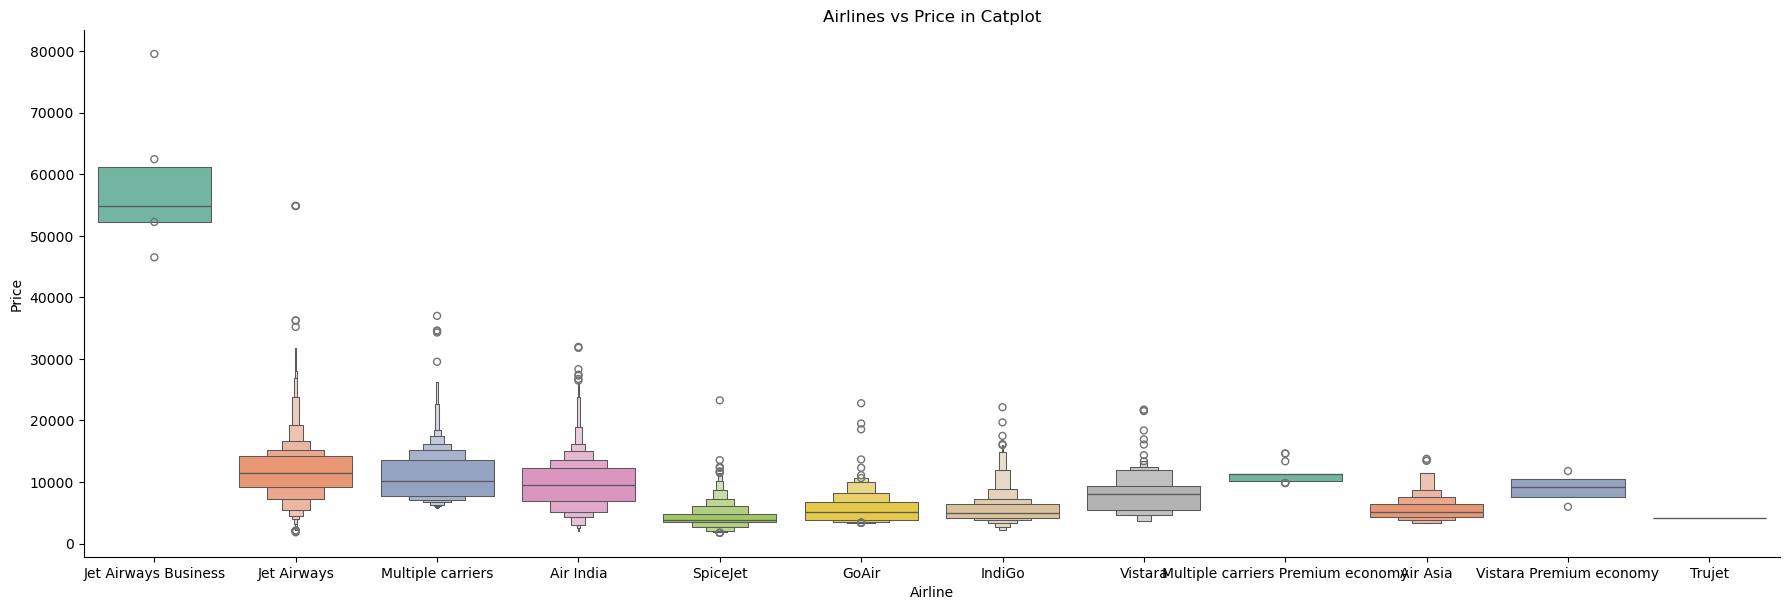

In [137]:
sns.catplot(y="Price",x="Airline",data=df.sort_values("Price",ascending=False),kind="boxen",height=6,aspect=3,palette='Set2')
plt.title("Airlines vs Price in Catplot")

In [138]:
Airline = df[["Airline"]]
Airline = pd.get_dummies(Airline,drop_first=True)
Airline.head()

,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy
0,False,False,True,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,True,False,False,False,False,False,False,False,False


In [139]:
Source = df[["Source"]]
Source = pd.get_dummies(Source,drop_first=True)
Source.head()

,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,False,False,False,False
1,False,False,True,False
2,False,True,False,False
3,False,False,True,False
4,False,False,False,False


In [140]:
Destination = df[["Destination"]]
Destination = pd.get_dummies(Destination,drop_first=True)
Destination.head()

,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,False,False,False,False,True
1,False,False,False,False,False
2,True,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,True


In [141]:
df.Total_Stops.value_counts()

Total_Stops
1 stop      5626
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

In [142]:
df.Total_Stops = df.Total_Stops.replace({"non-stop":0,"1 stop":1,"2 stops":2,"3 stops":3,"4 stops":4})

In [143]:
df.head()

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,20,2,50
1,Air India,Kolkata,Banglore,2,7662,1,5,5,50,7,25
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,25,19,0
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,5,5,25
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,50,4,45


In [144]:
df = pd.concat([df,Airline,Source,Destination],axis=1)

In [145]:
df.drop(["Airline","Source","Destination"],axis=1,inplace=True)

In [146]:
df.head()

,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,20,2,50,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,2,7662,1,5,5,50,7,25,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,2,13882,9,6,9,25,19,0,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False
3,1,6218,12,5,18,5,5,25,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
4,1,13302,1,3,16,50,4,45,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True


# _Feature Selection_

In [147]:
df.corr()

,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
Total_Stops,1.000000,0.603883,-0.009472,0.054389,-0.061490,-0.002591,0.739872,-0.136686,0.271084,-0.060113,-0.302998,0.215039,0.017876,0.118389,0.009088,-0.274356,0.002519,-0.120452,-0.020460,-0.234761,0.490166,0.032745,-0.260757,0.490166,-0.447394,-0.260757,-0.234761,-0.015310
Price,0.603883,1.000000,-0.153738,-0.103651,0.006819,-0.024492,0.508672,-0.124874,0.050346,-0.095146,-0.361048,0.416135,0.253302,0.139803,0.017651,-0.296552,-0.010380,-0.060646,-0.000453,-0.179216,0.270619,0.009377,-0.230745,0.270619,-0.313401,-0.230745,-0.179216,0.189785
Journey_day,-0.009472,-0.153738,1.000000,-0.038378,0.002220,-0.008261,-0.022181,-0.008996,-0.032668,-0.003111,0.007322,-0.017241,-0.031710,0.042190,0.030841,0.022177,-0.008568,-0.013151,-0.020113,0.006626,0.099981,-0.060505,-0.014008,0.099981,0.002662,-0.014008,0.006626,-0.075225
Journey_month,0.054389,-0.103651,-0.038378,1.000000,0.039112,-0.059238,0.016175,-0.040880,-0.045917,-0.004497,-0.048515,0.059716,-0.034788,0.053676,-0.051223,-0.011984,-0.014199,-0.017257,-0.019797,0.005646,0.139240,0.087161,-0.039358,0.139240,0.090480,-0.039358,0.005646,-0.453689
Dep_hours,-0.061490,0.006819,0.002220,0.039112,1.000000,-0.024806,0.002783,-0.023746,-0.013004,-0.016365,-0.023367,0.113980,-0.007522,-0.149969,-0.028669,-0.010434,0.000857,0.023918,-0.003374,-0.014835,-0.118836,0.155500,-0.017277,-0.118836,0.009489,-0.017277,-0.014835,-0.022120
Dep_mins,-0.002591,-0.024492,-0.008261,-0.059238,-0.024806,1.000000,-0.021946,0.092548,-0.045442,0.076733,-0.014763,0.024376,0.009165,-0.109400,-0.004628,0.092599,-0.010008,-0.077920,-0.011382,0.067086,-0.085405,-0.024298,0.037675,-0.085405,0.003162,0.037675,0.067086,0.107091
Duration_hours,0.739872,0.508672,-0.022181,0.016175,0.002783,-0.021946,1.000000,-0.126355,0.261934,-0.094053,-0.346258,0.307050,-0.011849,-0.008119,-0.002275,-0.263855,-0.008253,-0.020387,-0.016269,-0.186675,0.299931,0.123424,-0.233338,0.299931,-0.346205,-0.233338,-0.186675,0.004008
Duration_mins,-0.136686,-0.124874,-0.008996,-0.040880,-0.023746,0.092548,-0.126355,1.000000,-0.033273,0.067205,0.119781,-0.084097,-0.002324,-0.118786,-0.006855,0.041299,-0.007610,0.041937,0.004951,-0.098833,-0.154038,0.013722,-0.018777,-0.154038,0.218177,-0.018777,-0.098833,0.079844
Airline_Air India,0.271084,0.050346,-0.032668,-0.045917,-0.013004,-0.045442,0.261934,-0.033273,1.000000,-0.060235,-0.216026,-0.332394,-0.010499,-0.157260,-0.015460,-0.127540,-0.004285,-0.095962,-0.007423,-0.051097,0.001502,0.023472,0.022206,0.001502,-0.068431,0.022206,-0.051097,0.052993
Airline_GoAir,-0.060113,-0.095146,-0.003111,-0.004497,-0.016365,0.076733,-0.094053,0.067205,-0.060235,1.000000,-0.066332,-0.102063,-0.003224,-0.048288,-0.004747,-0.039162,-0.001316,-0.029466,-0.002279,-0.026154,-0.009063,-0.042912,-0.035930,-0.009063,0.099867,-0.035930,-0.026154,0.017576


<Axes: >

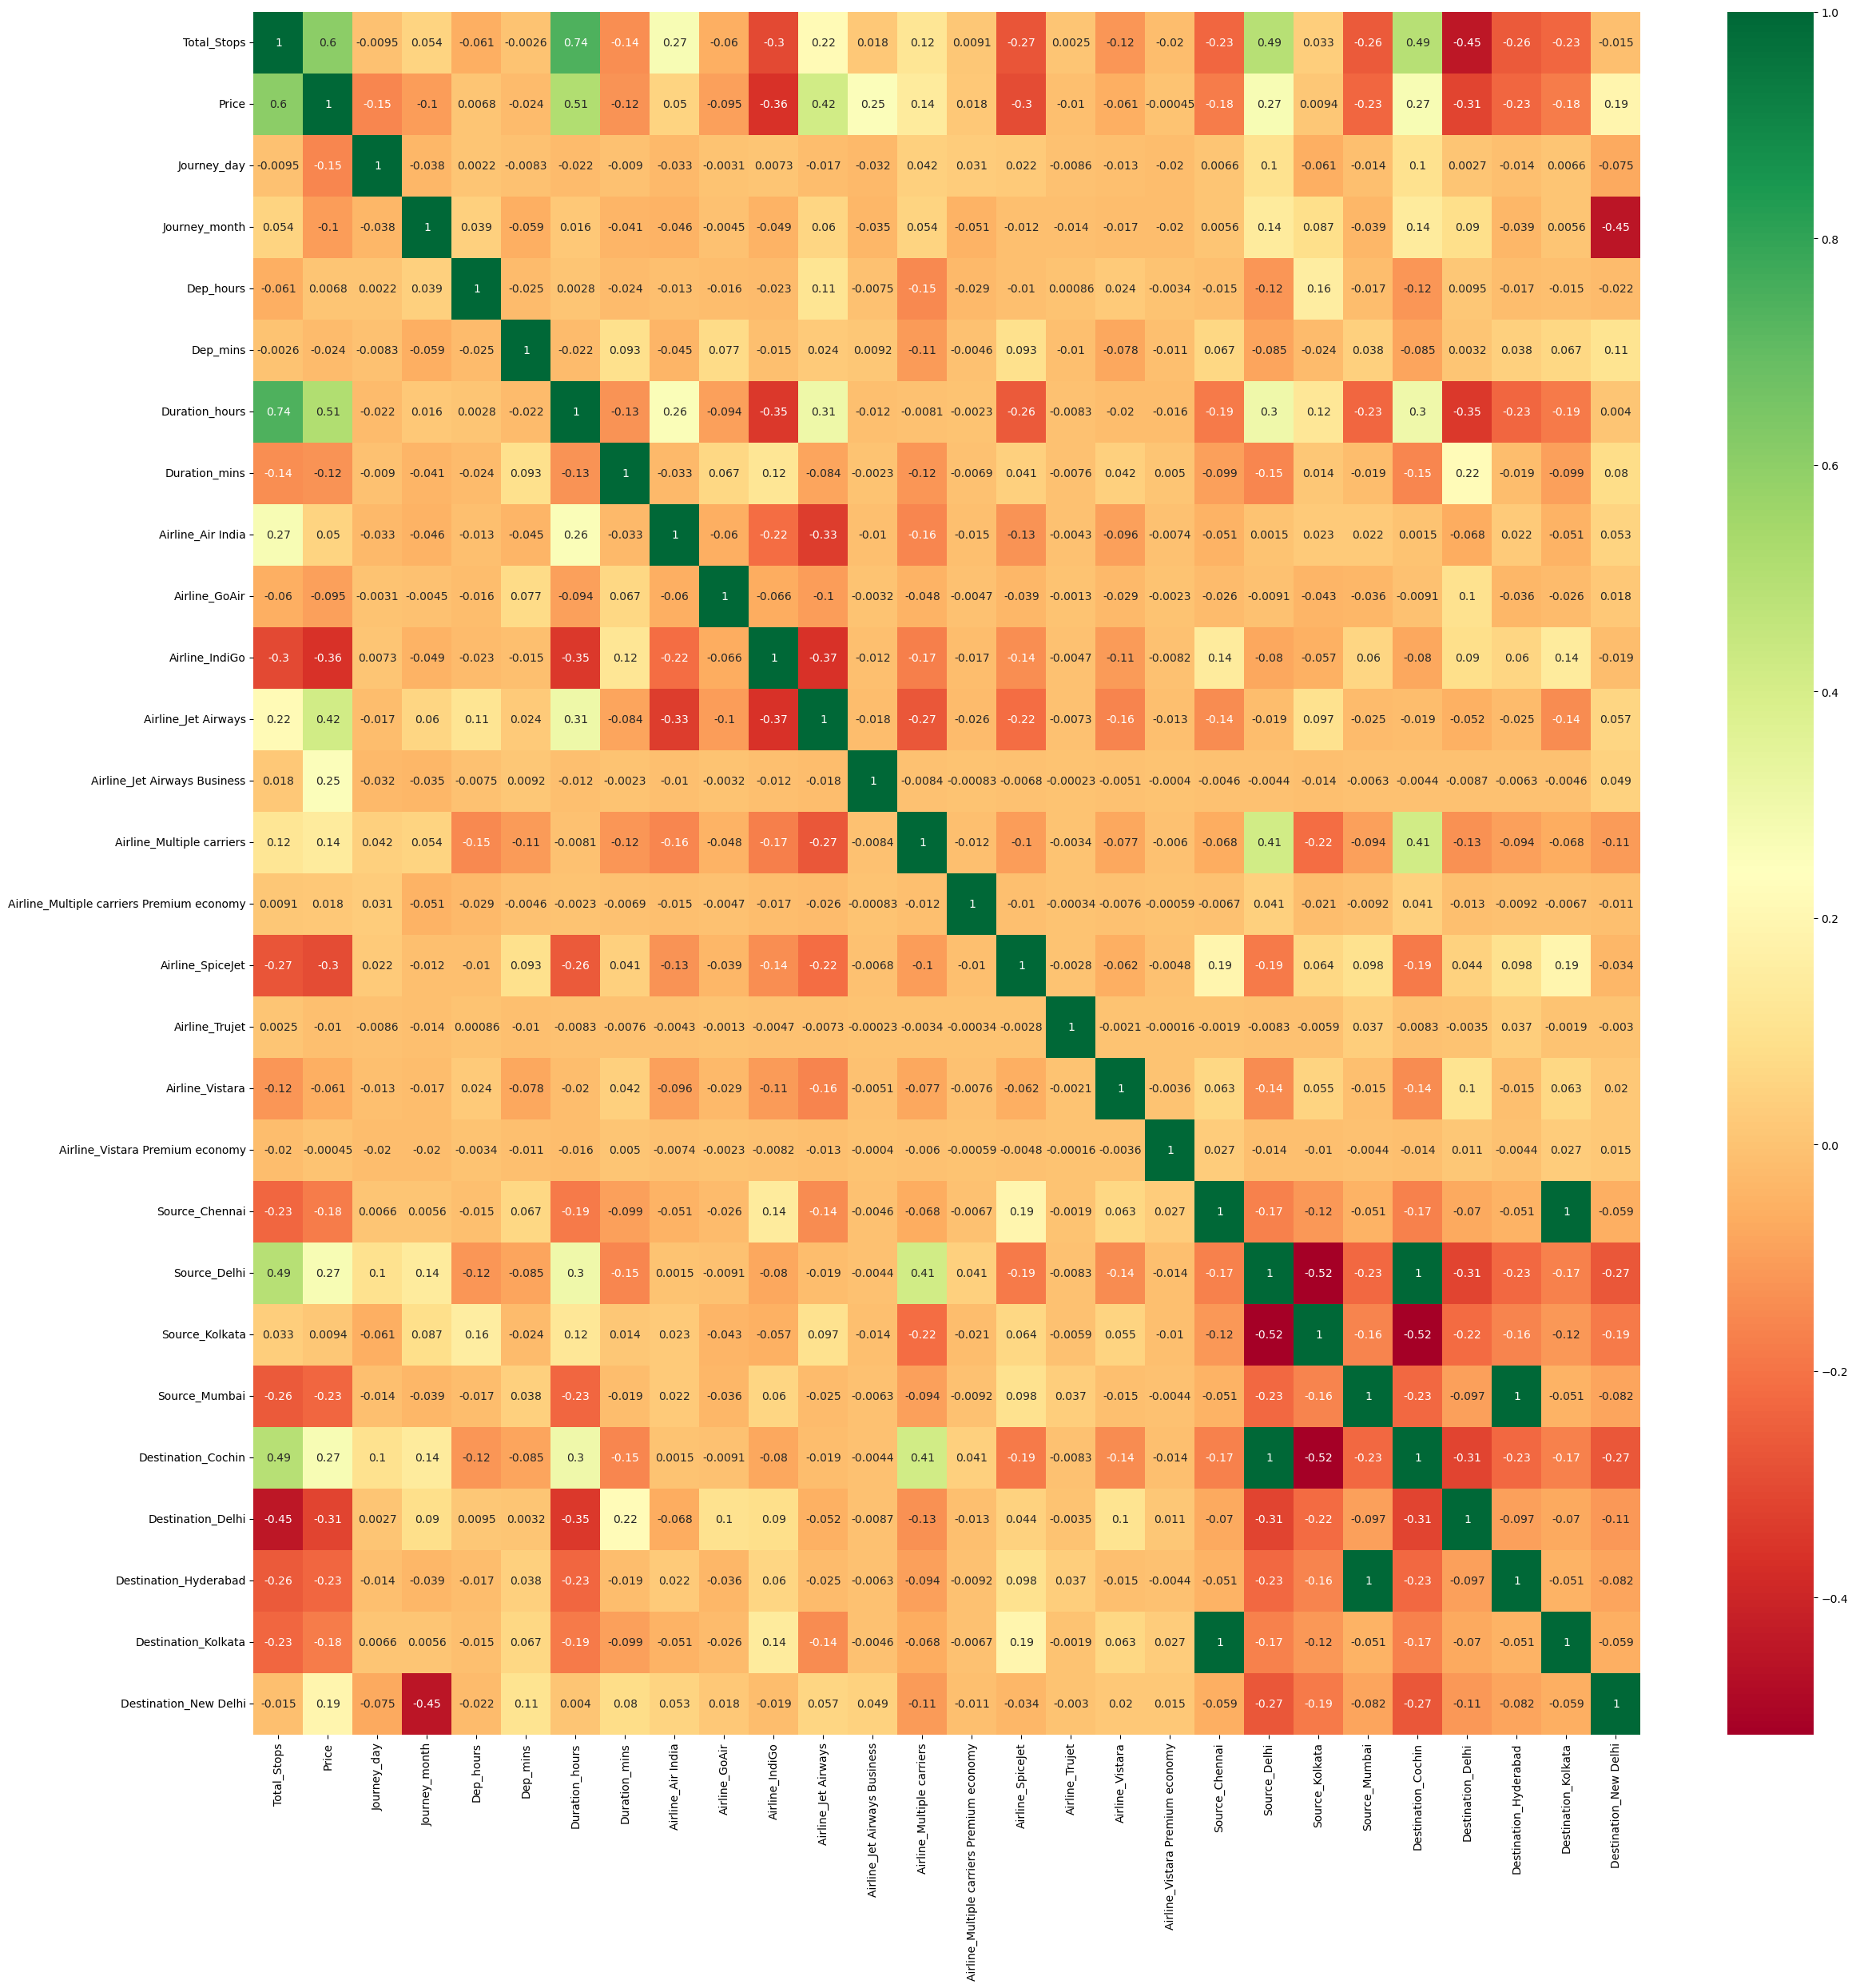

In [148]:
plt.figure(figsize=(28,28))
sns.heatmap(df.corr(),annot=True,cmap= "RdYlGn")

# __Insights__

In [149]:
x=df.drop("Price",axis=1)

In [150]:
x

,Total_Stops,Journey_day,Journey_month,Dep_hours,Dep_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,24,3,22,20,2,50,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,2,1,5,5,50,7,25,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,2,9,6,9,25,19,0,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False
3,1,12,5,18,5,5,25,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
4,1,1,3,16,50,4,45,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,9,4,19,55,2,30,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
10679,0,27,4,20,45,2,35,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
10680,0,27,4,8,20,3,0,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
10681,0,1,3,11,30,2,40,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True


In [151]:
y=df.Price
y

0         3897
1         7662
2        13882
3         6218
4        13302
         ...  
10678     4107
10679     4145
10680     7229
10681    12648
10682    11753
Name: Price, Length: 10683, dtype: int64

In [152]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=57)

# __Create Model__
__Linear Regression__

In [153]:
from sklearn.linear_model import LinearRegression
LR=LinearRegression()
LR.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [154]:
y_pred = LR.predict(x_test)
y_pred

array([13522.91094566,  8789.66596857,  3171.71061904, ...,
        5883.06610013,  6904.72128433,  5529.36757754], shape=(2137,))

In [155]:
y_test.values

array([7832, 7480, 3873, ..., 5678, 4030, 6297], shape=(2137,))

In [156]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [157]:
r2score=r2_score(y_test,y_pred)
r2score

0.6789070895003098

In [158]:
print(mean_squared_error(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
adjusted_r2 = 1-(1-0.67)*(2137-29)/(2137-29-1)
print(adjusted_r2)
mse=mean_squared_error(y_test,y_pred)
mse

7041013.082984089
1925.481597663055
0.6698433792121501


7041013.082984089

# __KNN__

In [159]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

In [160]:
scaled = scaler.fit_transform(x)

In [161]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(scaled,y,test_size=0.25,random_state=43)

In [162]:
from sklearn.neighbors import KNeighborsRegressor
KNN = KNeighborsRegressor(n_neighbors=3,weights="distance")
KNN.fit(x_train,y_train)
y_prd = KNN.predict(x_test)
r2score1 = r2_score(y_test,y_prd)
r2score1

0.7369894372793131

In [163]:
mse1 = mean_squared_error(y_test,y_prd)
mse1

6063544.354927703

# __DecisionTreeRegressor__

In [164]:
from sklearn.tree import DecisionTreeRegressor
dr = DecisionTreeRegressor(random_state=69)
dr.fit(x_train,y_train)
dr_pred = dr.predict(x_test)
r2score2 = r2_score(y_test,dr_pred)
print(r2_score(y_test,dr_pred))
print(mean_squared_error(y_test,dr_pred))
print(mean_absolute_error(y_test,dr_pred))
adjusted_r2 = 1-(1-0.75)*(2137-29)/(2137-29-1)
adjusted_r2

0.6997955538863805
6921026.120496797
1442.727361787096


0.7498813478879924

In [165]:
mse2 = mean_absolute_error(y_test,dr_pred)
mse2

1442.727361787096

# __Decision Tree Regressor with hyperperameter tunning__

In [166]:
from sklearn.model_selection import GridSearchCV 

In [167]:
params = {
          "splitter":("best","random"),
          "max_depth":(list(range(1,20))),
          "min_samples_split":[2,3,4],
          "min_samples_leaf":list(range(1,20)),
          "max_leaf_nodes":[None,10,20,30,40,50,60,70,80,90]}
tree_clf = DecisionTreeRegressor(random_state=3)
tree_cv = GridSearchCV(tree_clf,params,scoring="r2", n_jobs=-1,verbose=1,cv=3)
tree_cv.fit(x_train,y_train)
best_params = tree_cv.best_params_
print(f"Best parameters:{best_params})")


Fitting 3 folds for each of 21660 candidates, totalling 64980 fits
Best parameters:{'max_depth': 10, 'max_leaf_nodes': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'})


In [168]:
Bestparamters:({'criterion':'entropy','max_depth':12,'min_samples_leaf':1,'min_samples_split':3,'splitter': 'random',"max_leaf_nodes":None})
tree_cv.best_params_

{'max_depth': 10,
 'max_leaf_nodes': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'splitter': 'best'}

In [169]:
dt1=DecisionTreeRegressor(max_depth=12,max_leaf_nodes=None,min_samples_leaf= 1,min_samples_split=3,splitter='random',random_state=47)
dt1.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'random'
,max_depth,12
,min_samples_split,3
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,47
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [170]:
dt1.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'random'
,max_depth,12
,min_samples_split,3
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,47
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [171]:
y_hat1=dt1.predict(x_test)
y_hat1

array([ 9164.75      , 15237.13333333, 11258.26923077, ...,
        8861.0952381 , 11292.63568773, 12074.        ], shape=(2671,))

In [172]:
par =r2_score(y_test,y_hat1)
par

0.7537385337290194

In [196]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=101,random_state=99)
rf.fit(x_train,y_train)
rf_pred=rf.predict(x_test)
r2_score3 = r2_score(y_test,rf_pred)
r2_score3

0.8150797799653454

In [197]:
mse3=mean_squared_error(y_test,rf_pred)
mse3

4263220.247522499

# __Random Forest Regressor with Hyperparameters tunning__

In [173]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Hyperparameter values
n_estimators = [int(x) for x in np.linspace(start=200, stop=2000, num=10)]

max_features = ['sqrt', 'log2', None]

max_depth = [int(x) for x in np.linspace(10, 110, num=11)]
max_depth.append(None)

min_samples_split = [2, 5, 10]

min_samples_leaf = [1, 2, 4]

bootstrap = [True, False]

# Dictionary of parameters
random_grid = {
    'n_estimators': n_estimators,
    'max_features': max_features,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf,
    'bootstrap': bootstrap
}

# Model
rf_clf1 = RandomForestRegressor(random_state=42)

# Random Search CV
rf_cv = RandomizedSearchCV(
    estimator=rf_clf1,
    param_distributions=random_grid,
    n_iter=100,
    cv=3,
    scoring='r2',
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_cv.fit(x_train, y_train)

# Best parameters
rf_best_params = rf_cv.best_params_

print("Best Parameters:", rf_best_params)

# Best score
print("Best R2 Score:", rf_cv.best_score_)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'n_estimators': 800, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 70, 'bootstrap': False}
Best R2 Score: 0.7981478398168895


In [174]:
rf_cv.best_params_

{'n_estimators': 800,
 'min_samples_split': 10,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 70,
 'bootstrap': False}

In [175]:
rf_cv.best_score_

np.float64(0.7981478398168895)

In [176]:
rf1=RandomForestRegressor(n_estimators=1000,min_samples_leaf=1,min_samples_split=10,max_features="sqrt",max_depth=80,bootstrap=False,random_state=99)

In [177]:
rf1.fit(x_train,y_train)

,n_estimators,1000
,criterion,'squared_error'
,max_depth,80
,min_samples_split,10
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [178]:
y_rf_random=rf1.predict(x_test)
y_rf_random

array([ 8895.15879206, 13072.67265476, 11314.19226944, ...,
       10032.01415159, 10139.13242738, 11098.26859881], shape=(2671,))

In [179]:
par1=r2_score(y_test,y_rf_random)
par1

0.828457321594452

# __XGBoost__

In [180]:
!pip3 install xgboost

import xgboost as xg 
from xgboost import XGBRFRegressor
xgb_r =xg.XGBRegressor(objective='reg:linear',
                       n_estimators = 90,seed = 123)
xgb_r.fit(x_train,y_train)
xgb_pred = xgb_r.predict(x_test)

r2_score4 = r2_score(y_test,xgb_pred)
r2_score4



0.8439516425132751

In [181]:
mse4=mean_squared_error(y_test,xgb_pred)
mse4

3597597.25

# __XGBoost with Hyperperameter Tunning__

In [182]:
param_grid = {'gamma':[0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6,51.2,102.4,200],
              'learning_rate':[0.01,0.03,0.06,0.1,0.15,0.2,0.25,0.300000012,0.4,0.5,0.6,0.7],
              'max_depth':[5,6,7,8,9,10,11,12,13,14],
              'n_estimators':[50,65,80,100,115,130,150],
              'reg_alpha':[0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6,51.2,102.4,200],
              'reg_lambda':[0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6,51.2,102.4,200]}

In [183]:
XGB = xg.XGBRegressor(random_state=42,verbosity=0,silent=0)
rcv=RandomizedSearchCV(estimator=XGB,scoring='r2',param_distributions=param_grid,n_iter=100,cv=5,
                       verbose=2,n_jobs=-1)

In [184]:
rcv.fit(x_train,y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [5, 6, ...], 'n_estimators': [50, 65, ...], ...}"
,n_iter,100
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [185]:
cv_best_params = rcv.best_params_
print(f"Best Paramters:{cv_best_params})")

Best Paramters:{'reg_lambda': 3.2, 'reg_alpha': 1.6, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.25, 'gamma': 12.8})


In [186]:
XGB2 = xg.XGBRegressor(reg_lambda=1.6,reg_alpha=102.4,n_estimators=80,max_depth=9,learning_rate=0.1,gamma=6)

In [187]:
XGB2.fit(x_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [188]:
y_predictxgb=XGB2.predict(x_test)
x_predictxgb=XGB2.predict(x_train)

In [189]:
print("Train r2_score :",r2_score(y_train,x_predictxgb))
print("test r2_score :",r2_score(y_test,y_predictxgb))
r2 = r2_score(y_test,y_predictxgb)
r2


Train r2_score : 0.9229971170425415
test r2_score : 0.8516741991043091


0.8516741991043091

In [190]:
from sklearn.metrics import r2_score

print("Train r2_score :", r2_score(y_train, x_predictxgb))
print("Test r2_score :", r2_score(y_test, y_predictxgb))

r2 = r2_score(y_test, y_predictxgb)
print(r2)

Train r2_score : 0.9229971170425415
Test r2_score : 0.8516741991043091
0.8516741991043091


### ARTIFICIAL NEURAL NETWORK

In [191]:
## CREATION OF MODEL 
from sklearn.neural_network import MLPRegressor 
model = MLPRegressor(hidden_layer_sizes=(150,3),
                     learning_rate_init=0.1,
                     max_iter=500,
                     random_state=33)
model.fit(x_train,y_train)

,loss,'squared_error'
,hidden_layer_sizes,"(150, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.1
,power_t,0.5
,max_iter,500
,shuffle,True


In [192]:
y_predict_proba = model.predict(x_test)
y_train_predict = model.predict(x_train)
print("train r2_score :",r2_score(y_train,y_train_predict))
print("test r2_score :",r2_score(y_test,y_predict_proba))

train r2_score : 0.8164471009919777
test r2_score : 0.8115733088950732


In [193]:
r2_score5 = r2_score(y_test,y_predict_proba)
r2_score5


0.8115733088950732

In [199]:
mse5=mean_squared_error(y_test,y_predict_proba)
mse5

4344059.749342988

### MODEL COMPARISION REPORT

In [200]:
score = pd.DataFrame({"model":["LinearRegression","KNN","DecisionTreeRegressor","RandomForestRegressor","XGBRegressor","ANN_MLPRegressor"],
                     "R2_Score":[r2score*100,r2score1*100,r2score2*100,r2_score3*100,r2_score4*100,r2_score5*100],
                      "With Hyperparameter tunning":["No Available","No Available",par*100,par1*100,r2*100,"No Available"],
                      "MSE":[mse,mse1,mse2,mse3,mse4,mse5]})
                      

In [201]:
score

,model,R2_Score,With Hyperparameter tunning,MSE
0,LinearRegression,67.890709,No Available,7.041013e+06
1,KNN,73.698944,No Available,6.063544e+06
2,DecisionTreeRegressor,69.979555,75.373853,1.442727e+03
3,RandomForestRegressor,81.507978,82.845732,4.263220e+06
4,XGBRegressor,84.395164,85.16742,3.597597e+06
5,ANN_MLPRegressor,81.157331,No Available,4.344060e+06
